In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

In [2]:
# Загружаем обучающую и тестовую части Fashion-MNIST
(x_train_full, y_train_full), (x_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

print(f'{x_train_full.shape} x {y_train_full.shape}\n'
      f'{x_test.shape} x {y_test.shape}')

(60000, 28, 28) x (60000,)
(10000, 28, 28) x (10000,)


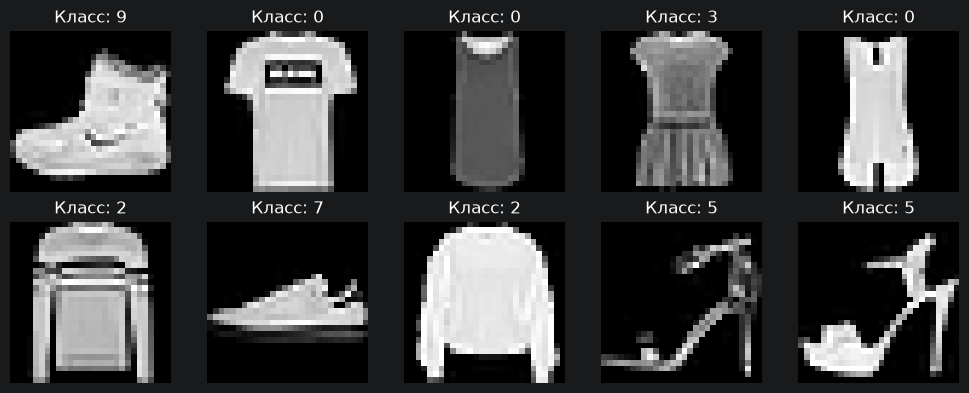

In [3]:
# Выводим несколько изображений с числовыми метками
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(x_train_full[i], cmap='gray')
    ax.set_title(f'Класс: {y_train_full[i]}')
    ax.axis('off')

plt.tight_layout()
plt.show()

In [4]:
# Тип данных и диапазон пикселей
print(f'{x_train_full.dtype}, {x_test.dtype}\n'
      f'{x_train_full.min()}, {x_train_full.max()}')

uint8, uint8
0, 255


In [5]:
# Выделяем validation из обучающей части
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full,
    y_train_full,
    test_size=10000,
    random_state=42,
    stratify=y_train_full
)

print(f'{x_val.shape}, {y_val.shape}\n')

(10000, 28, 28), (10000,)



In [6]:
# Нормируем пиксели до диапазона 0-1 и добавляем ось канала для Conv2D
x_train_ready = (
        x_train.astype('float32') / 255.0
)[..., np.newaxis]
x_val_ready = (
        x_val.astype('float32') / 255.0
)[..., np.newaxis]
x_test_ready = (
        x_test.astype('float32') / 255.0
)[..., np.newaxis]

print(f'{x_train_ready.shape}, {x_val_ready.shape}, {x_test_ready.shape}\n'
      f'Диапазон train: {x_train_ready.min()}, {x_train_ready.max()}')

(50000, 28, 28, 1), (10000, 28, 28, 1), (10000, 28, 28, 1)
Диапазон train: 0.0, 1.0


In [7]:
# Фиксируем случайность для воспроизводимости
tf.keras.utils.set_random_seed(42)

# Создаем модель
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(filters=32, kernel_size=(3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       346,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 347,146 (1.32 MB)

 Trainable params: 347,146 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Настраиваем Adam оптимизатор, функцию потерь и метрику
initial_weights = model.get_weights()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

In [9]:
# Обучаем сеть с Adam 10 эпох
history_adam = model.fit(
    x_train_ready,
    y_train,
    validation_data=(x_val_ready, y_val),
    epochs=10,
    batch_size=32
)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8518 - loss: 0.4215 - val_accuracy: 0.8832 - val_loss: 0.3329
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8971 - loss: 0.2893 - val_accuracy: 0.8891 - val_loss: 0.3063
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9120 - loss: 0.2447 - val_accuracy: 0.8954 - val_loss: 0.2846
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9232 - loss: 0.2123 - val_accuracy: 0.8954 - val_loss: 0.2910
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9337 - loss: 0.1838 - val_accuracy: 0.8970 - val_loss: 0.2997
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9435 - loss: 0.1602 - val_accuracy: 0.8988 - val_loss: 0.3045
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9518 - loss: 0.1384 - val_accuracy: 0.9037 - val_loss: 0.2979
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9583 - loss: 0.1198 - 

In [10]:
# Сохраняем модель
model_adam = model

# Создаем отдельную модель и загружаем начальные веса
tf.keras.utils.set_random_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(filters=32, kernel_size=(3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.set_weights(initial_weights)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       346,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 347,146 (1.32 MB)

 Trainable params: 347,146 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Настраиваем RMSprop
model.compile(
    optimizer=tf.keras.optimizers.RMSprop(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

In [12]:
# Обучаем сеть с RMSprop 10 эпох
history_rmsprop = model.fit(
    x_train_ready,
    y_train,
    validation_data=(x_val_ready, y_val),
    epochs=10,
    batch_size=32
)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8455 - loss: 0.4328 - val_accuracy: 0.8897 - val_loss: 0.3110
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8976 - loss: 0.2903 - val_accuracy: 0.9022 - val_loss: 0.2680
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9119 - loss: 0.2475 - val_accuracy: 0.9063 - val_loss: 0.2561
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9225 - loss: 0.2183 - val_accuracy: 0.9100 - val_loss: 0.2478
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9315 - loss: 0.1944 - val_accuracy: 0.9099 - val_loss: 0.2544
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9400 - loss: 0.1744 - val_accuracy: 0.9123 - val_loss: 0.2586
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9468 - loss: 0.1568 - val_accuracy: 0.9115 - val_loss: 0.2679
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9523 - loss: 0.1426 - 

In [13]:
# Сохраняем модель
model_rmsprop = model

# Создаем отдельную модель и загружаем начальные веса
tf.keras.utils.set_random_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(filters=32, kernel_size=(3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.set_weights(initial_weights)
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │       346,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 347,146 (1.32 MB)

 Trainable params: 347,146 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# Настраиваем SGD
model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

In [15]:
# Обучаем сеть с SGD 10 эпох
history_sgd = model.fit(
    x_train_ready,
    y_train,
    validation_data=(x_val_ready, y_val),
    epochs=10,
    batch_size=32
)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.5133 - loss: 1.6876 - val_accuracy: 0.6658 - val_loss: 1.0435
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7100 - loss: 0.8475 - val_accuracy: 0.7530 - val_loss: 0.7261
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7633 - loss: 0.6837 - val_accuracy: 0.7862 - val_loss: 0.6312
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7874 - loss: 0.6165 - val_accuracy: 0.8008 - val_loss: 0.5805
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8005 - loss: 0.5772 - val_accuracy: 0.8087 - val_loss: 0.5478
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8086 - loss: 0.5501 - val_accuracy: 0.8166 - val_loss: 0.5241
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8162 - loss: 0.5296 - val_accuracy: 0.8224 - val_loss: 0.5058
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8214 - loss: 0.5133 - 

In [16]:
# Сохраняем модель
model_sgd = model

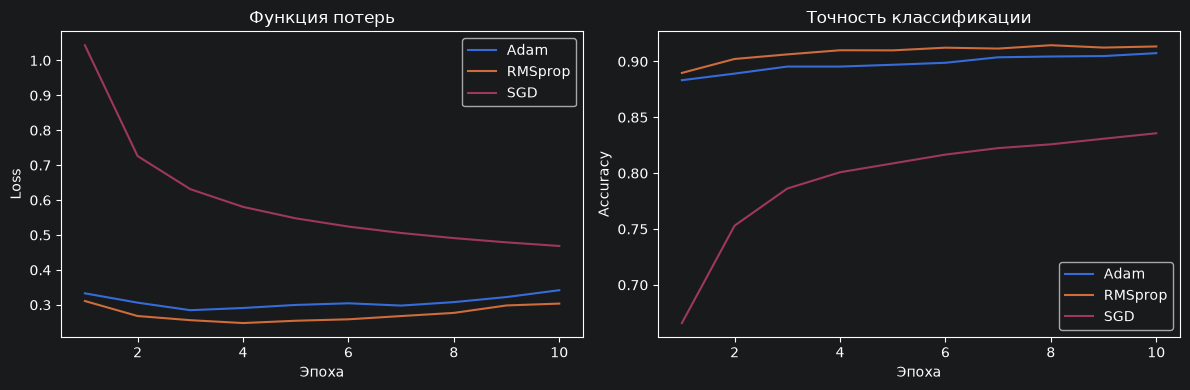

In [17]:
# Сравниваем оптимизаторы на validation
epochs = np.arange(1, len(history_adam.history['loss']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(epochs, history_adam.history['val_loss'], label='Adam')
ax[0].plot(epochs, history_rmsprop.history['val_loss'], label='RMSprop')
ax[0].plot(epochs, history_sgd.history['val_loss'], label='SGD')
ax[0].set_title('Функция потерь')
ax[0].set_xlabel('Эпоха')
ax[0].set_ylabel('Loss')
ax[0].legend()

ax[1].plot(epochs, history_adam.history['val_accuracy'], label='Adam')
ax[1].plot(epochs, history_rmsprop.history['val_accuracy'], label='RMSprop')
ax[1].plot(epochs, history_sgd.history['val_accuracy'], label='SGD')
ax[1].set_title('Точность классификации')
ax[1].set_xlabel('Эпоха')
ax[1].set_ylabel('Accuracy')
ax[1].legend()

plt.tight_layout()
plt.show()

In [18]:
# Сравниваем итоговые модели на test
test_results = []

for name, network in [
    ('Adam', model_adam),
    ('RMSprop', model_rmsprop),
    ('SGD', model_sgd),
]:
    test_loss, test_accuracy = network.evaluate(
        x_test_ready, y_test, verbose=0
    )

    test_results.append({
        'Model': name,
        'Test loss': test_loss,
        'Test accuracy': test_accuracy
    })

pd.DataFrame(test_results)

,Model,Test loss,Test accuracy
0,Adam,0.368360,0.9014
1,RMSprop,0.331382,0.9059
2,SGD,0.505615,0.8235


Для Fashion-MNIST обучена сверточная сеть Conv2D > MaxPooling2D > Flatten > Dense(64) > Dense(10). При learning rate = 0,001 и 10 эпохах лучший результат показал RMSprop: тестовая accuracy - 90,59%, у Adam - 90,14%, у SGD - 82,35%. У Adam и RMSprop наблюдались признаки переобучения, тогда как SGD продолжал улучшаться. Полученные результаты относятся к выбранным настройкам и не означают, что SGD всегда уступает другим оптимизаторам.